# Part 1: Model building

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_DIR = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"  
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Testing")

print(os.listdir(TRAIN_DIR))
print(os.listdir(TEST_DIR))

['pituitary', 'notumor', 'meningioma', 'glioma']
['pituitary', 'notumor', 'meningioma', 'glioma']


In [3]:
def load_image_dataset(base_folder):
    data = []

    # Loop through each class folder in the base directory
    for class_folder in os.listdir(base_folder):
        class_path = os.path.join(base_folder, class_folder)

        # Check if the path is a directory
        if os.path.isdir(class_path):
            # Loop through each image file in the class folder
            for image_file in os.listdir(class_path):
                image_path = os.path.join(class_path, image_file)

                # Append the image path and class label to the data list
                data.append((image_path, class_folder))

    df = pd.DataFrame(data, columns=['image_path', 'class'])
    return df

In [4]:
train_df = load_image_dataset(TRAIN_DIR)
train_df.shape

(5600, 2)

In [5]:
train_df

,image_path,class
0,/kaggle/input/datasets/masoudnickparvar/brain-...,pituitary
1,/kaggle/input/datasets/masoudnickparvar/brain-...,pituitary
2,/kaggle/input/datasets/masoudnickparvar/brain-...,pituitary
3,/kaggle/input/datasets/masoudnickparvar/brain-...,pituitary
4,/kaggle/input/datasets/masoudnickparvar/brain-...,pituitary
...,...,...
5595,/kaggle/input/datasets/masoudnickparvar/brain-...,glioma
5596,/kaggle/input/datasets/masoudnickparvar/brain-...,glioma
5597,/kaggle/input/datasets/masoudnickparvar/brain-...,glioma
5598,/kaggle/input/datasets/masoudnickparvar/brain-...,glioma


In [6]:
test_df = load_image_dataset(TEST_DIR)
test_df.shape

(1600, 2)

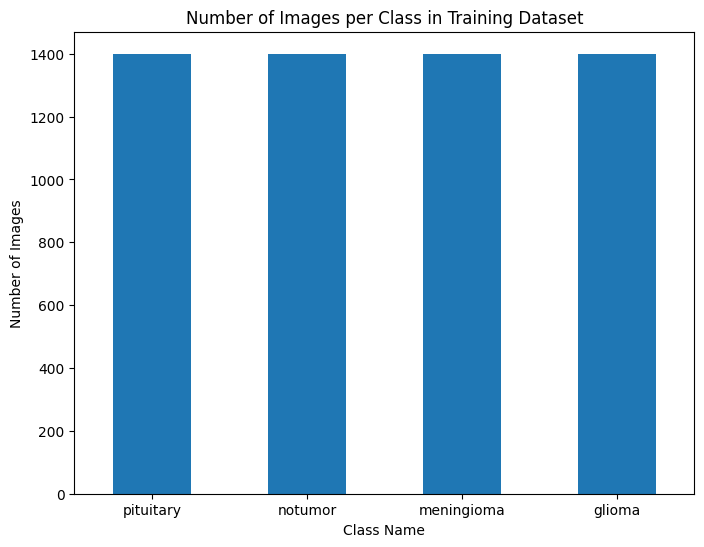

In [7]:
%matplotlib inline

class_counts = train_df['class'].value_counts()

# Plotting the bar chart for training dataset
plt.figure(figsize=(8, 6))
class_counts.plot(kind='bar')
plt.title('Number of Images per Class in Training Dataset')
plt.xlabel('Class Name')
plt.ylabel('Number of Images')
plt.xticks(rotation=360)
plt.show()

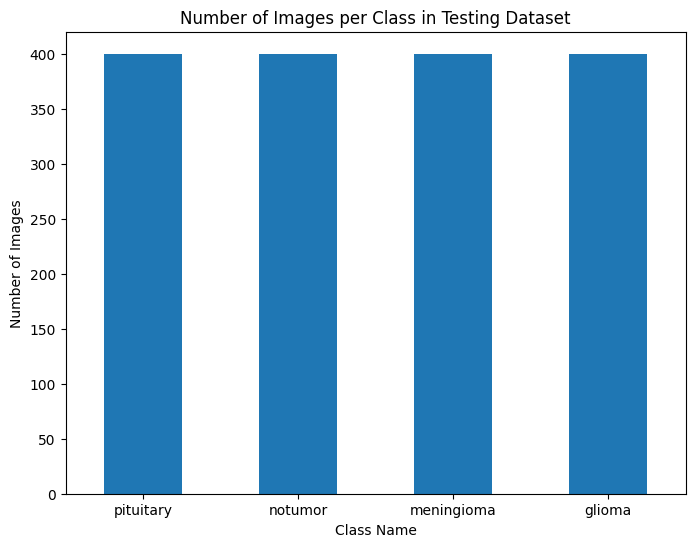

In [8]:
class_counts = test_df['class'].value_counts()

# Plotting the bar chart for testing dataset
plt.figure(figsize=(8, 6))
class_counts.plot(kind='bar')
plt.title('Number of Images per Class in Testing Dataset')
plt.xlabel('Class Name')
plt.ylabel('Number of Images')
plt.xticks(rotation=360)
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from PIL import Image
tf.keras.utils.set_random_seed(42)

In [10]:
val_df, test_df = train_test_split(test_df, test_size=0.5, stratify=test_df['class'], random_state=42)

In [11]:
val_df.shape, test_df.shape

((800, 2), (800, 2))

## Xception Model - Transfer Learning

In [12]:
batch_size = 32

img_size = (299, 299)

# for training data: rescale + random brightness
image_generator = ImageDataGenerator(
    rescale=1/255,
    brightness_range=(0.8, 1.2)
)

# for validation and test data: rescale only
test_datagen = ImageDataGenerator(rescale=1/255)

In [13]:
train_gen = image_generator.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='class',
    batch_size=batch_size,
    target_size=img_size,
    shuffle=True,
    validate_filenames=False
)

valid_gen = test_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='class',
    batch_size=batch_size,
    target_size=img_size,
    shuffle=True,
    validate_filenames=False
)

test_gen = test_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='class',
    batch_size=16,
    target_size=img_size,
    shuffle=False,
    validate_filenames=False
)

Found 5600 non-validated image filenames belonging to 4 classes.
Found 800 non-validated image filenames belonging to 4 classes.
Found 800 non-validated image filenames belonging to 4 classes.


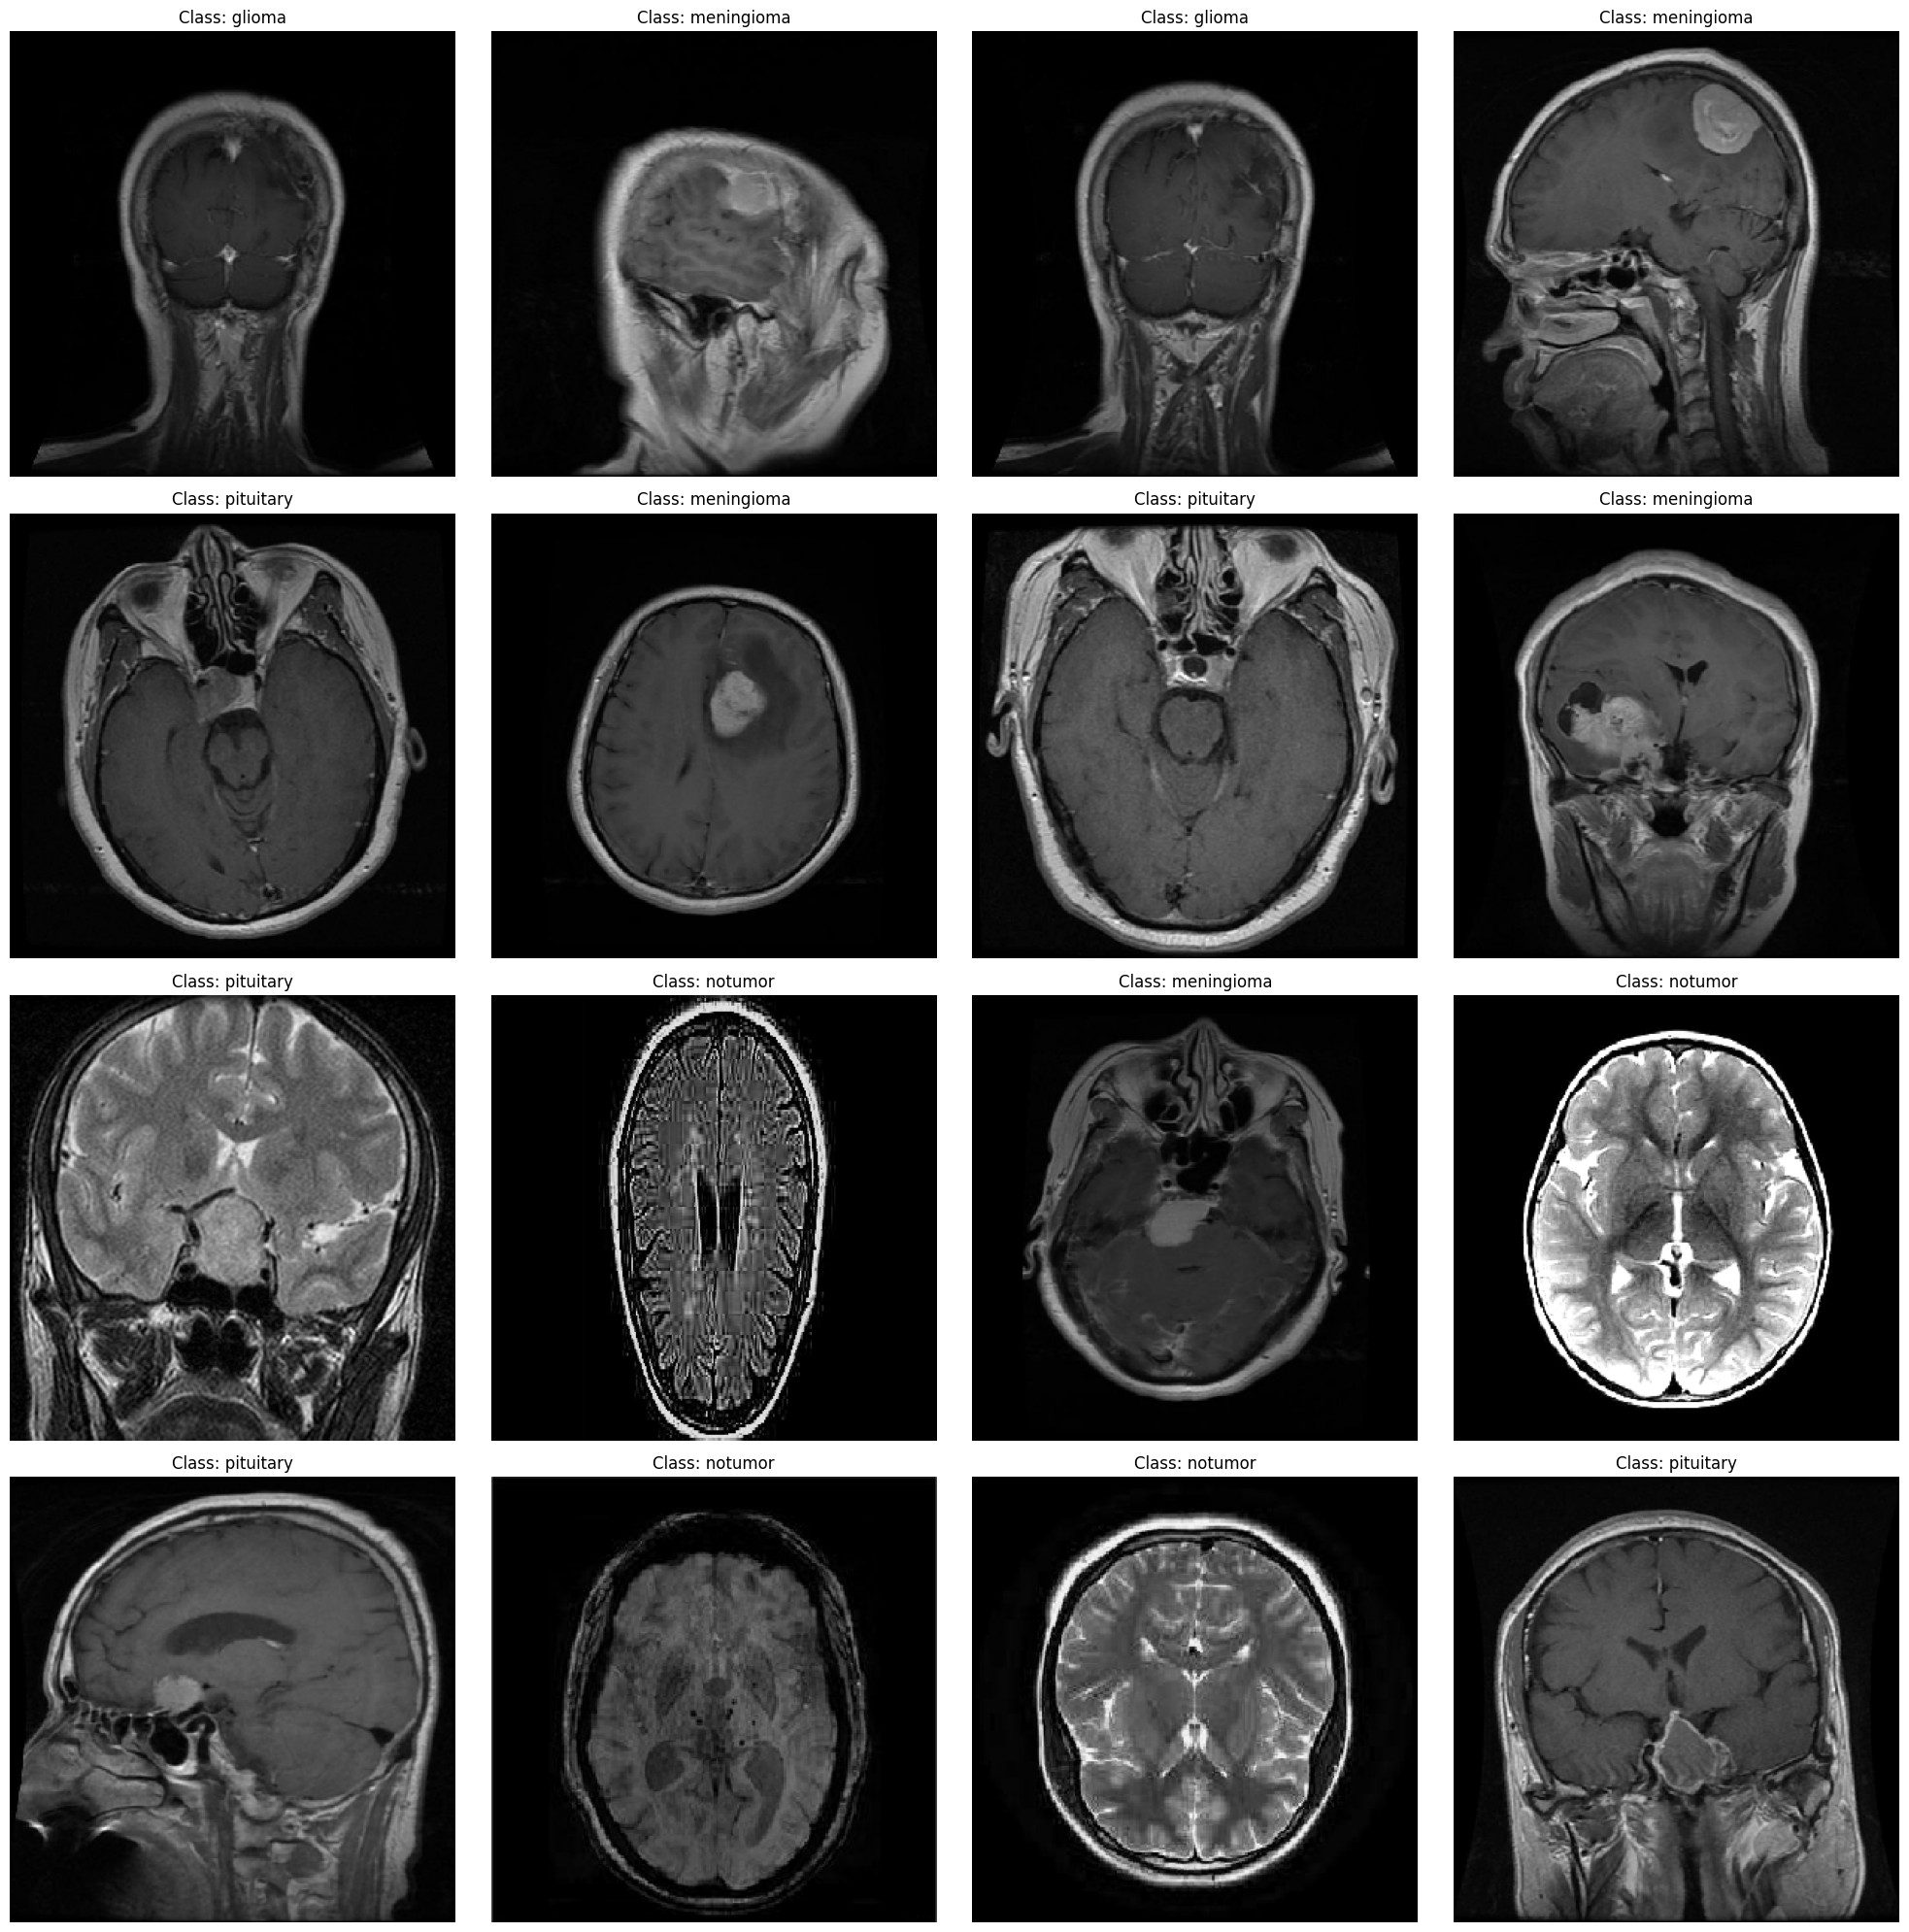

In [14]:
plt.figure(figsize=(20, 20))

for i in range(16):
  plt.subplot(4, 4, i+1)
  batch = next(train_gen)
  image = batch[0][0]
  label = batch[1][0]
  plt.imshow(image)

  # Get the class index
  class_index = np.argmax(label)

  #Get the list of class names and class indices
  class_names = list(train_gen.class_indices.keys())
  class_indices = list(train_gen.class_indices.values())

  # Find the index of the class_index in the list of indices
  index_position = class_indices.index(class_index)

  #Get the class name using the index position
  class_name = class_names[index_position]

  plt.title(f"Class: {class_name}")
  plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
img_shape = (299, 299, 3)

xception_base_model = tf.keras.applications.Xception(
    include_top=False,
    weights='imagenet',
    input_shape=img_shape,
    pooling='max'
)

model = Sequential([
    xception_base_model,
    Flatten(),
    Dropout(rate=0.3),
    Dense(128, activation='relu'),
    Dropout(rate=0.25),
    Dense(4, activation='softmax')
])

I0000 00:00:1792279637.226404      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792279637.233947      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,124,268 (80.58 MB)

 Trainable params: 21,069,740 (80.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [17]:
model.compile(
    Adamax(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', Precision(name='precision'), Recall(name='recall')]
)

In [18]:
hist = model.fit(
    train_gen,
    epochs=5,
    validation_data=valid_gen
)

Epoch 1/5


2026-10-17 23:27:59.220663: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[32,128,147,147]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,128,147,147]{3,2,1,0}, f32[128,128,1,1]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-17 23:27:59.378108: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.157583467s
Trying algorithm eng3{k11=2} for conv (f32[32,128,147,147]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,128,147,147]{3,2,1,0}, f32[128,128,1,1]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_

175/175 ━━━━━━━━━━━━━━━━━━━━ 273s 940ms/step - accuracy: 0.8970 - loss: 0.3082 - precision: 0.9263 - recall: 0.8664 - val_accuracy: 0.7250 - val_loss: 1.2243 - val_precision: 0.7298 - val_recall: 0.7225
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 152s 869ms/step - accuracy: 0.9820 - loss: 0.0593 - precision: 0.9832 - recall: 0.9804 - val_accuracy: 0.9200 - val_loss: 0.3937 - val_precision: 0.9218 - val_recall: 0.9137
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 151s 864ms/step - accuracy: 0.9914 - loss: 0.0209 - precision: 0.9918 - recall: 0.9911 - val_accuracy: 0.9450 - val_loss: 0.3440 - val_precision: 0.9448 - val_recall: 0.9413
Epoch 4/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 152s 865ms/step - accuracy: 0.9943 - loss: 0.0169 - precision: 0.9945 - recall: 0.9939 - val_accuracy: 0.9488 - val_loss: 0.3467 - val_precision: 0.9499 - val_recall: 0.9488
Epoch 5/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 152s 865ms/step - accuracy: 0.9952 - loss: 0.0160 - precision: 0.9955 - recall: 0.9950 - val_accuracy: 0.9413 - val_los

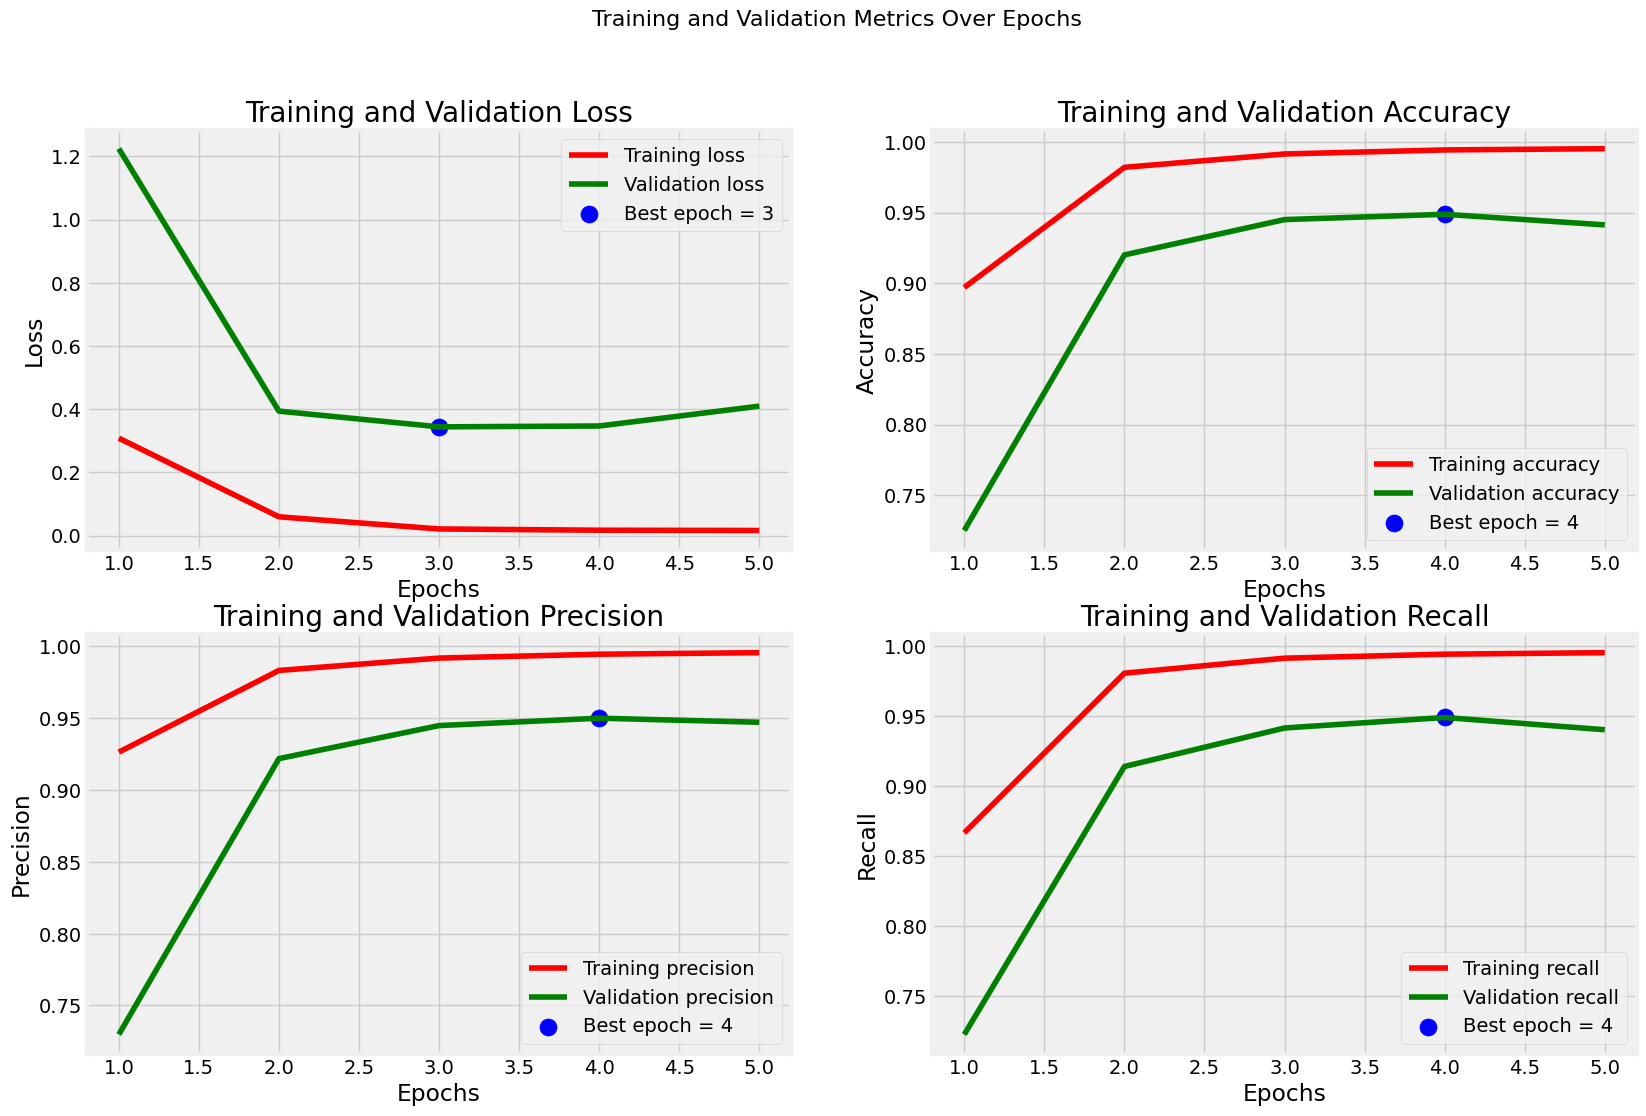

In [19]:
# Get training and validation metrics from history
metrics = ['loss', 'accuracy', 'precision', 'recall']
train_metrics = {m: hist.history[m] for m in metrics}
val_metrics = {m: hist.history[f'val_{m}'] for m in metrics}


# find best epochs and values
best_epochs = {}
best_values = {}
for m in metrics:
  if m == 'loss':
    idx = np.argmin(val_metrics[m])
  else:
    idx = np.argmax(val_metrics[m])
  best_epochs[m] = idx + 1
  best_values[m] = val_metrics[m][idx]


# Plot metrics
plt.figure(figsize=(20, 12))
plt.style.use('fivethirtyeight')

for i, metric in enumerate(metrics, 1):
  plt.subplot(2, 2, i)
  epochs = range(1, len(train_metrics[metric]) + 1)

  plt.plot(epochs, train_metrics[metric], 'r', label=f'Training {metric}')
  plt.plot(epochs, val_metrics[metric], 'g', label=f'Validation {metric}')
  plt.scatter(best_epochs[metric], best_values[metric], s=150, color='blue', label=f'Best epoch = {best_epochs[metric]}')
  plt.title(f'Training and Validation {metric.title()}')
  plt.xlabel('Epochs')
  plt.ylabel(metric.title())
  plt.legend()
  plt.grid(True)


plt.suptitle('Training and Validation Metrics Over Epochs', fontsize=16)
plt.show()

In [20]:
train_score = model.evaluate(train_gen, verbose=1)
valid_score = model.evaluate(valid_gen, verbose=1)
test_score = model.evaluate(test_gen, verbose=1)


print(f"Train Accuracy: {train_score[1] * 100:.2f}%")
print(f"Train Loss: {train_score[0]:.2f}")
print(f"\n\nValidation Accuracy: {valid_score[1] * 100:.2f}%")
print(f"Validation Loss: {valid_score[0]:.2f}")
print(f"\n\nTest Accuracy: {test_score[1] * 100:.2f}%")
print(f"Test Loss: {test_score[0]:.2f}")

175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 244ms/step - accuracy: 0.9959 - loss: 0.0159 - precision: 0.9959 - recall: 0.9959
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 239ms/step - accuracy: 0.9413 - loss: 0.4095 - precision: 0.9471 - recall: 0.9400


2026-10-17 23:42:59.793286: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:00.010159: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:02.662936: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:02.850923: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:04.275060: E external/local_xla/xla/stream_

50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 235ms/step - accuracy: 0.9413 - loss: 0.4420 - precision: 0.9435 - recall: 0.9400
Train Accuracy: 99.59%
Train Loss: 0.02


Validation Accuracy: 94.13%
Validation Loss: 0.41


Test Accuracy: 94.13%
Test Loss: 0.44


50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step


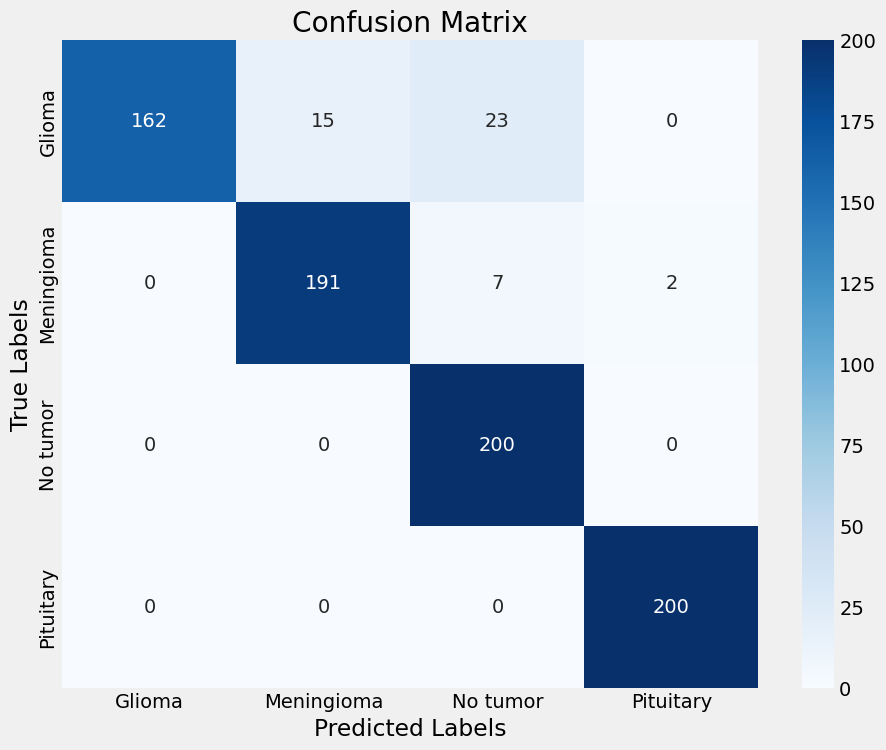

In [21]:
preds = model.predict(test_gen)
y_pred = np.argmax(preds, axis=1)

class_dict = {
    0: 'Glioma',
    1: 'Meningioma',
    2: 'No tumor',
    3: 'Pituitary'
}

cm = confusion_matrix(test_gen.classes, y_pred)
labels = list(class_dict.values())

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')

plt.savefig('/kaggle/working/confusion_matrix_xception.png', bbox_inches='tight')
plt.show()

In [22]:
from PIL import Image

def predict(img_path: str) -> None:
  #Get class labels
  labels = list(class_dict.values())

  #Create figure
  plt.figure(figsize=(6,8))

  #Load and preprocess image
  img = Image.open(img_path).convert('RGB')
    
  resized_img = img.resize((299,299))
  img_array = np.asarray(resized_img)
  img_array = np.expand_dims(img_array, axis=0) / 255.0

  #Get model predictions
  predictions = model.predict(img_array)
  probabilities = list(predictions[0])

  #Get predicted class
  predicted_class_idx = np.argmax(probabilities)
  predicted_class = class_dict [predicted_class_idx]

  # Plot original image
  plt.subplot(2, 1, 1)
  plt.imshow(resized_img)
  plt.title(f"Input MRI Image\nPredicted: {predicted_class}")

  # Plot prediction probabilities
  plt.subplot(2, 1, 2)
  bars = plt.barh(labels, probabilities)
  plt.xlabel("Probability", fontsize=15)
  plt.title("Class Probabilities")

  # Add probability labels to bars
  ax = plt.gca()
  ax.bar_label(bars, fmt="%.2f")

  plt.tight_layout()
  plt.show()

  print(f"\nPredicted tumor type: {predicted_class}")

2026-10-17 23:43:57.042015: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:57.185203: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:58.016380: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:58.149348: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 23:43:59.028723: E external/local_xla/xla/stream_

1/1 ━━━━━━━━━━━━━━━━━━━━ 21s 21s/step


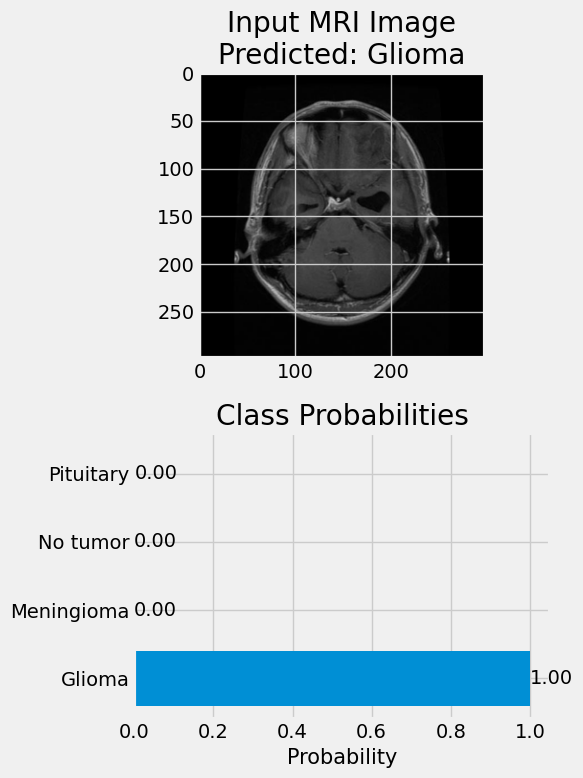


Predicted tumor type: Glioma


In [23]:
predict(test_df[test_df['class'] == 'glioma']['image_path'].iloc[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


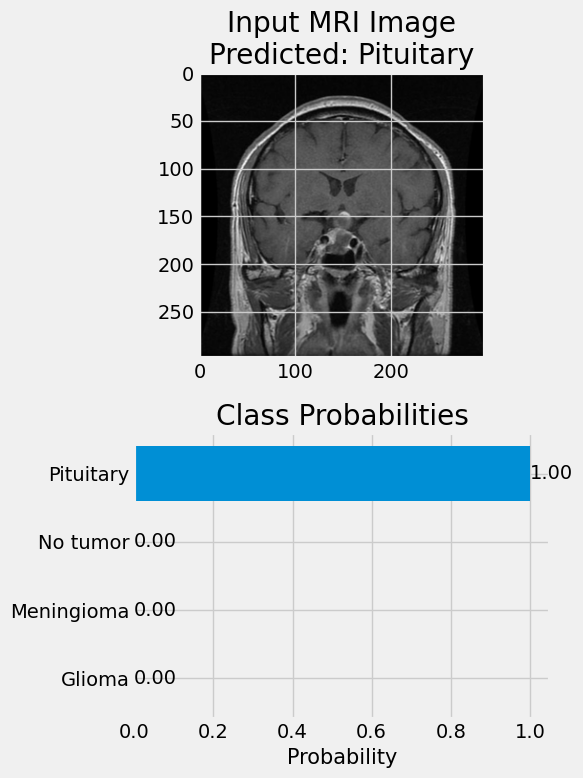


Predicted tumor type: Pituitary


In [24]:
predict(test_df[test_df['class'] == 'pituitary']['image_path'].iloc[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


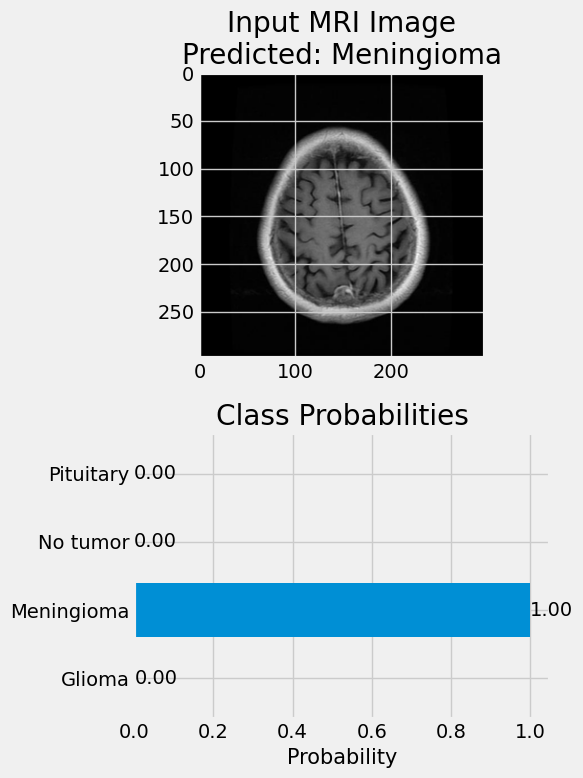


Predicted tumor type: Meningioma


In [25]:
predict(test_df[test_df['class'] == 'meningioma']['image_path'].iloc[0])

In [26]:
model.save_weights('/kaggle/working/xception_model.weights.h5')

## Custom CNN model

In [27]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras import regularizers

In [28]:
batch_size = 16

img_size = (224, 224)

# for training data: rescale + random brightness
image_generator = ImageDataGenerator(
    rescale=1/255,
    brightness_range=(0.8, 1.2)
)

# for validation and test data: rescale only
test_datagen = ImageDataGenerator(rescale=1/255)

In [29]:
train_gen = image_generator.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='class',
    batch_size=batch_size,
    target_size=img_size,
    shuffle=True,
    validate_filenames=False
)

valid_gen = test_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='class',
    batch_size=batch_size,
    target_size=img_size,
    shuffle=True,
    validate_filenames=False
)

test_gen = test_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='class',
    batch_size=16,
    target_size=img_size,
    shuffle=False,
    validate_filenames=False
)

Found 5600 non-validated image filenames belonging to 4 classes.
Found 800 non-validated image filenames belonging to 4 classes.
Found 800 non-validated image filenames belonging to 4 classes.


In [30]:
# Custom CNN model

cnn_model = Sequential()

# Convolutional layers with ReLU activation and pooling
cnn_model.add(Conv2D(1024, kernel_size=3, padding='same', activation='relu', input_shape=(224, 224, 3)))
cnn_model.add(MaxPooling2D(pool_size=2, strides=2))

cnn_model.add(Conv2D(512, kernel_size=3, padding='same', activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2, strides=2))

cnn_model.add(Conv2D(256, kernel_size=3, padding='same', activation='relu'))
cnn_model.add(Conv2D(128, kernel_size=3, padding='same', activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2, strides=2))

cnn_model.add(Conv2D(64, kernel_size=3, padding='same', activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2, strides=2))

# Flatten and fully connected layers
cnn_model.add(Flatten())
cnn_model.add(Dense(256, activation='relu'))
cnn_model.add(Dense(128, activation='relu'))
cnn_model.add(Dense(4, activation='softmax'))

# Print the model summary
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 1024) │        28,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 1024) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 512)  │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 56, 56, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     3,211,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,541,444 (36.40 MB)

 Trainable params: 9,541,444 (36.40 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
cnn_model.compile(
    Adamax(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', Precision(name='precision'), Recall(name='recall')]
)

In [32]:
hist = cnn_model.fit(
    train_gen,
    epochs=5,
    validation_data=valid_gen
)

Epoch 1/5


2026-10-17 23:44:23.845521: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng18{k2=1,k4=3,k5=1,k6=0,k7=0} for conv (f32[16,512,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,1024,112,112]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-17 23:44:24.166353: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.320968992s
Trying algorithm eng18{k2=1,k4=3,k5=1,k6=0,k7=0} for conv (f32[16,512,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,1024,112,112]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_label

350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 912ms/step - accuracy: 0.5476 - loss: 0.9923 - precision: 0.6511 - recall: 0.3746

2026-10-17 23:51:02.901507: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng18{k2=1,k4=3,k5=1,k6=0,k7=0} for conv (f32[16,512,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,1024,112,112]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-17 23:51:03.206631: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.305231771s
Trying algorithm eng18{k2=1,k4=3,k5=1,k6=0,k7=0} for conv (f32[16,512,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,1024,112,112]{3,2,1,0}, f32[512,1024,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_label

350/350 ━━━━━━━━━━━━━━━━━━━━ 450s 1s/step - accuracy: 0.6843 - loss: 0.7396 - precision: 0.7647 - recall: 0.5871 - val_accuracy: 0.7550 - val_loss: 0.8296 - val_precision: 0.7807 - val_recall: 0.7300
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 336s 960ms/step - accuracy: 0.8452 - loss: 0.4042 - precision: 0.8620 - recall: 0.8296 - val_accuracy: 0.7862 - val_loss: 0.7302 - val_precision: 0.8008 - val_recall: 0.7588
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 336s 960ms/step - accuracy: 0.9014 - loss: 0.2724 - precision: 0.9086 - recall: 0.8948 - val_accuracy: 0.7825 - val_loss: 0.6860 - val_precision: 0.7963 - val_recall: 0.7525
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 337s 962ms/step - accuracy: 0.9441 - loss: 0.1579 - precision: 0.9468 - recall: 0.9404 - val_accuracy: 0.8550 - val_loss: 0.9927 - val_precision: 0.8568 - val_recall: 0.8525
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 337s 963ms/step - accuracy: 0.9634 - loss: 0.1007 - precision: 0.9639 - recall: 0.9623 - val_accuracy: 0.8737 - val_loss: 

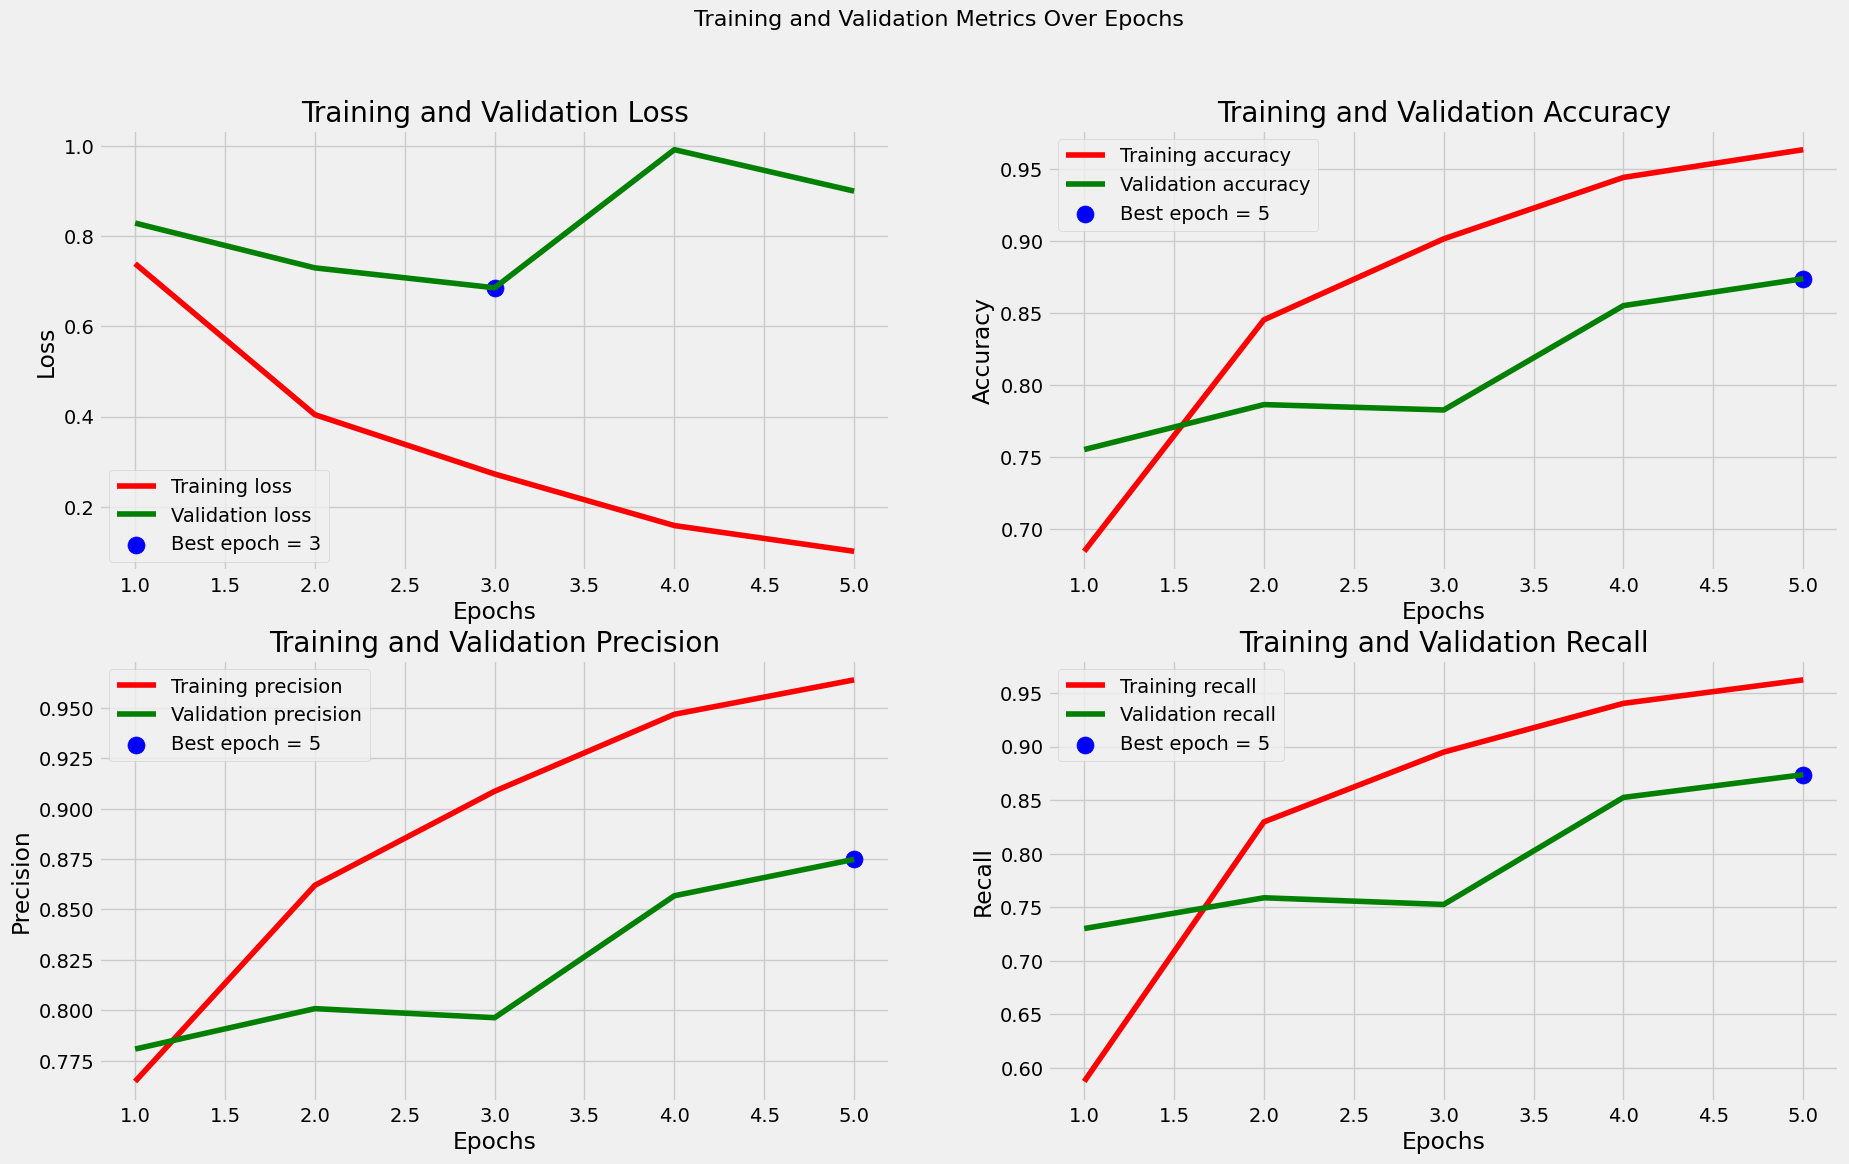

In [33]:
# Get training and validation metrics from history
metrics = ['loss', 'accuracy', 'precision', 'recall']
train_metrics = {m: hist.history[m] for m in metrics}
val_metrics = {m: hist.history[f'val_{m}'] for m in metrics}


# find best epochs and values
best_epochs = {}
best_values = {}
for m in metrics:
  if m == 'loss':
    idx = np.argmin(val_metrics[m])
  else:
    idx = np.argmax(val_metrics[m])
  best_epochs[m] = idx + 1
  best_values[m] = val_metrics[m][idx]


# Plot metrics
plt.figure(figsize=(20, 12))
plt.style.use('fivethirtyeight')

for i, metric in enumerate(metrics, 1):
  plt.subplot(2, 2, i)
  epochs = range(1, len(train_metrics[metric]) + 1)

  plt.plot(epochs, train_metrics[metric], 'r', label=f'Training {metric}')
  plt.plot(epochs, val_metrics[metric], 'g', label=f'Validation {metric}')
  plt.scatter(best_epochs[metric], best_values[metric], s=150, color='blue', label=f'Best epoch = {best_epochs[metric]}')
  plt.title(f'Training and Validation {metric.title()}')
  plt.xlabel('Epochs')
  plt.ylabel(metric.title())
  plt.legend()
  plt.grid(True)


plt.suptitle('Training and Validation Metrics Over Epochs', fontsize=16)
plt.show()

In [34]:
train_score = cnn_model.evaluate(train_gen, verbose=1)
valid_score = cnn_model.evaluate(valid_gen, verbose=1)
test_score = cnn_model.evaluate(test_gen, verbose=1)


print(f"Train Accuracy: {train_score[1] * 100:.2f}%")
print(f"Train Loss: {train_score[0]:.2f}")
print(f"\n\nValidation Accuracy: {valid_score[1] * 100:.2f}%")
print(f"Validation Loss: {valid_score[0]:.2f}")
print(f"\n\nTest Accuracy: {test_score[1] * 100:.2f}%")
print(f"Test Loss: {test_score[0]:.2f}")

350/350 ━━━━━━━━━━━━━━━━━━━━ 125s 357ms/step - accuracy: 0.9825 - loss: 0.0485 - precision: 0.9830 - recall: 0.9823
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 360ms/step - accuracy: 0.8737 - loss: 0.9006 - precision: 0.8748 - recall: 0.8737
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 356ms/step - accuracy: 0.8612 - loss: 0.9087 - precision: 0.8656 - recall: 0.8612
Train Accuracy: 98.25%
Train Loss: 0.05


Validation Accuracy: 87.37%
Validation Loss: 0.90


Test Accuracy: 86.12%
Test Loss: 0.91


50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 354ms/step


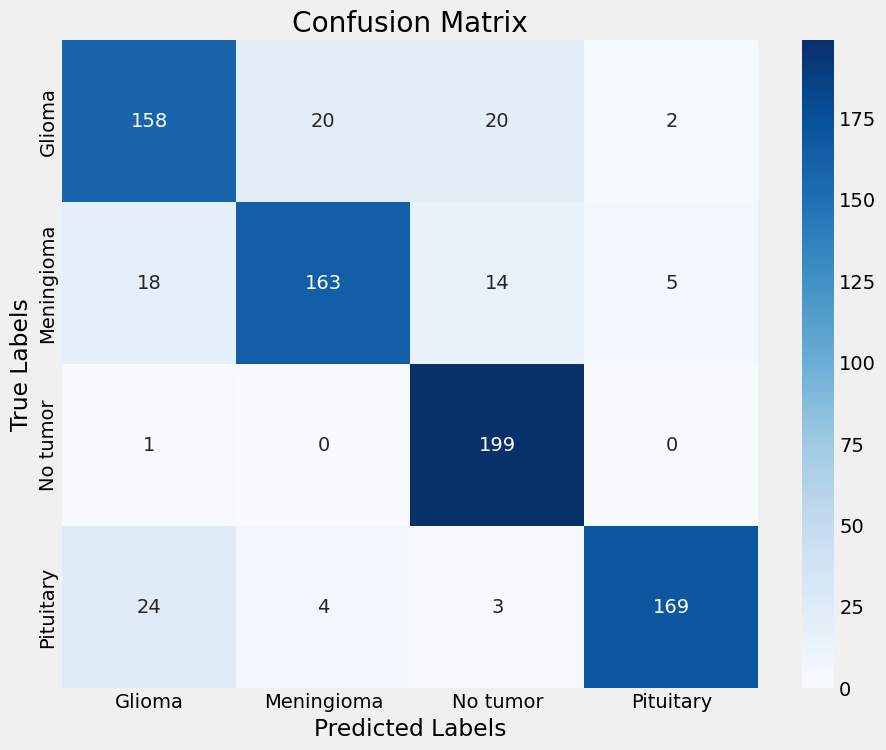

In [35]:
preds = cnn_model.predict(test_gen)
y_pred = np.argmax(preds, axis=1)

class_dict = {
    0: 'Glioma',
    1: 'Meningioma',
    2: 'No tumor',
    3: 'Pituitary'
}

cm = confusion_matrix(test_gen.classes, y_pred)
labels = list(class_dict.values())

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.savefig('/kaggle/working/confusion_matrix_cnn.png', bbox_inches='tight')
plt.show()

In [36]:
clr = classification_report(test_gen.classes, y_pred, target_names=labels)
print(clr)

              precision    recall  f1-score   support

      Glioma       0.79      0.79      0.79       200
  Meningioma       0.87      0.81      0.84       200
    No tumor       0.84      0.99      0.91       200
   Pituitary       0.96      0.84      0.90       200

    accuracy                           0.86       800
   macro avg       0.87      0.86      0.86       800
weighted avg       0.87      0.86      0.86       800



In [37]:
cnn_model.save('/kaggle/working/cnn_model.h5')